# Notebook 1 · Questions 1 and 2: problem, data audit, visualisation, split and pipeline
**IDA117V group project (group Auditors): predicting municipal audit outcomes one audit cycle ahead.**
This notebook follows Questions 1 and 2 of the technical report (`reports/IDA117V_Technical_Report.pdf`).
It runs the same scripts as `run_all.py`, so every number matches the report.

## Question 1: the problem in brief
* **Problem.** The Auditor-General (AGSA) audits all 257 municipalities each year, but the result arrives long after the financial year
  ends, so National Treasury usually responds after the damage is done.
* **Decision-maker.** National Treasury's local government support function and the provincial treasuries, who decide where to send
  financial-management support.
* **Classification task.** Unit: one municipality in financial year *t*. Inputs: nine audited financial indicators for year *t* plus the
  year *t* audit outcome. Target: the AGSA outcome for year *t+1*, **at_risk** (qualified, adverse, disclaimer, outstanding) or
  **not_at_risk** (unqualified, with or without findings). Horizon: one audit cycle.
* **Primary metric:** macro-F1 (both classes count equally); recall and precision for *at_risk* are the service-delivery indicators.
* **Data:** National Treasury's *Municipal Money* (free to reuse, no personal data). Full card: `docs/dataset_card.md`.

In [1]:
import sys, json, logging, warnings
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
logging.disable(logging.WARNING)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", "{:.3f}".format)
RESULTS, FIGS = ROOT / "results", ROOT / "reports" / "figures"
show = lambda name, width=800: display(Image(filename=str(FIGS / name), width=width))

In [2]:
df = pd.read_csv(ROOT / "data" / "processed" / "modeling_dataset.csv")
print("Rows:", len(df), "| municipalities:", df["demarcation.code"].nunique(), "| feature years:", sorted(df["financial_year_end.year"].unique()))
display(df.head())
display(df["target_next_year"].value_counts().to_frame("records").assign(share=lambda t: t.records / t.records.sum()))

Rows: 1434 | municipalities: 257 | feature years: [np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]


,demarcation.code,financial_year_end.year,total_revenue,total_expenditure,operating_surplus,cash_coverage_ratio,collection_rate,debtor_days,repairs_maintenance_ratio,irregular_expenditure_ratio,grant_dependency,prior_audit_outcome,prior_audit_opinion_raw,Name,target_next_year,target_opinion_raw
0,BUF,2018,5504777560.000,6105514561.000,-600737001.000,3.582,1.000,0.000,0.000,0.035,0.000,at_risk,qualified,Buffalo City,at_risk,qualified
1,BUF,2019,6011582409.000,6877780480.000,-866198071.000,2.044,1.000,0.000,0.056,0.019,0.000,at_risk,qualified,Buffalo City,at_risk,qualified
2,BUF,2020,6668511530.000,7830442944.000,-1161931414.000,2.105,1.000,0.000,0.000,0.039,1.813,at_risk,qualified,Buffalo City,at_risk,qualified
3,BUF,2021,7884806636.000,8276988077.000,-392181441.000,1.661,1.000,469.724,0.047,0.038,0.957,at_risk,qualified,Buffalo City,not_at_risk,unqualified_emphasis_of_matter
4,BUF,2022,8249186391.000,9201095919.000,-951909528.000,0.910,0.771,587.671,0.044,0.709,1.098,not_at_risk,unqualified_emphasis_of_matter,Buffalo City,at_risk,qualified


,records,share
target_next_year,,
not_at_risk,781,0.545
at_risk,653,0.455


## 2.1 Data dictionary and data audit
The audit script writes the data dictionary and the audit report (missing values, duplicates, invalid values, 3 × IQR outliers, leakage).

In [3]:
import audit_q21_v2
audit_q21_v2.main()
display(pd.read_csv(ROOT / "reports" / "data_dictionary.csv"))

MODELLING DATASET AUDIT (lagged t -> t+1)
Shape: (1434, 16)

=== CLASS BALANCE (target_next_year) ===
  not_at_risk: 781 rows (54.5%)
  at_risk: 653 rows (45.5%)

  prior_audit_outcome (year t, used as a feature):
prior_audit_outcome
not_at_risk    766
at_risk        668

=== DUPLICATES ===
  Duplicate municipality-year keys: 0
  Fully duplicate rows: 0

=== MISSINGNESS ===
  Average missingness across feature columns: 0.9%
  Missingness by feature:
    cash_coverage_ratio: 0.1% missing
    collection_rate: 8.4% missing
    repairs_maintenance_ratio: 0.1% missing
    irregular_expenditure_ratio: 0.1% missing
  Row counts by year (t, not t+1):
financial_year_end.year
2018    236
2019    231
2020    239
2021    244
2022    244
2023    240

=== INVALID VALUES ===
  Feature columns that are all zero (check these): []
  Columns with negative values (may be valid, e.g. operating deficit): {'total_revenue': np.int64(18), 'total_expenditure': np.int64(11), 'operating_surplus': np.int64(1032), 

,column,role,dtype,non_null_count,missing_pct,n_unique,example_value
0,demarcation.code,identifier/target,str,1434,0.000,257,BUF
1,financial_year_end.year,identifier/target,int64,1434,0.000,6,2018
2,total_revenue,feature,float64,1434,0.000,1427,5504777560.0
3,total_expenditure,feature,float64,1434,0.000,1429,6105514561.0
4,operating_surplus,feature,float64,1434,0.000,1429,-600737001.0
5,cash_coverage_ratio,feature,float64,1433,0.100,1415,3.581674279132065
6,collection_rate,feature,float64,1314,8.400,657,1.0
7,debtor_days,feature,float64,1434,0.000,784,0.0
8,repairs_maintenance_ratio,feature,float64,1433,0.100,1139,0.0
9,irregular_expenditure_ratio,feature,float64,1433,0.100,1357,0.03493900045094


In [4]:
print((ROOT / "reports" / "audit_report.txt").read_text())

MODELLING DATASET AUDIT (lagged t -> t+1)
Shape: (1434, 16)

=== CLASS BALANCE (target_next_year) ===
  not_at_risk: 781 rows (54.5%)
  at_risk: 653 rows (45.5%)

  prior_audit_outcome (year t, used as a feature):
prior_audit_outcome
not_at_risk    766
at_risk        668

=== DUPLICATES ===
  Duplicate municipality-year keys: 0
  Fully duplicate rows: 0

=== MISSINGNESS ===
  Average missingness across feature columns: 0.9%
  Missingness by feature:
    cash_coverage_ratio: 0.1% missing
    collection_rate: 8.4% missing
    repairs_maintenance_ratio: 0.1% missing
    irregular_expenditure_ratio: 0.1% missing
  Row counts by year (t, not t+1):
financial_year_end.year
2018    236
2019    231
2020    239
2021    244
2022    244
2023    240

=== INVALID VALUES ===
  Feature columns that are all zero (check these): []
  Columns with negative values (may be valid, e.g. operating deficit): {'total_revenue': np.int64(18), 'total_expenditure': np.int64(11), 'operating_surplus': np.int64(1032), 

**Leakage check.** All inputs describe year *t* and the target is year *t+1*; identifiers, the year and the raw opinion of *t+1* are
excluded; preprocessing is learned on training rows only. `prior_audit_outcome` (the year *t* result) is past information, so it is
not leakage, but it is a strong "repeat last year" signal; its effect is measured in Questions 3, 4 and 6.

## 2.2 Visualisations
Five figures, each with a title, units and labels; the interpretations are in the report (section 2.2).

Saved 5 charts to figures/:
 - 01_target_distribution.png
 - 02_missingness_by_feature.png
 - 03_surplus_vs_risk.png
 - 04_debtordays_vs_risk.png
 - 05_risk_trend_by_year.png
 - q4_confusion_matrices.png
 - q4_learning_curves.png
 - q4_model_comparison.png
 - q4_neural_training_curves.png
 - q4_pr_curves.png
 - q4_roc_curves.png
 - q5_optimisation_history.png
 - q5_test_confusion_matrix.png
 - q6_ablation.png
 - q6_mcnemar_table.png
 - q8_calibration.png
 - q8_fairness.png

Row count per year (sample size behind chart 5):
financial_year_end.year
2018    236
2019    231
2020    239
2021    244
2022    244
2023    240


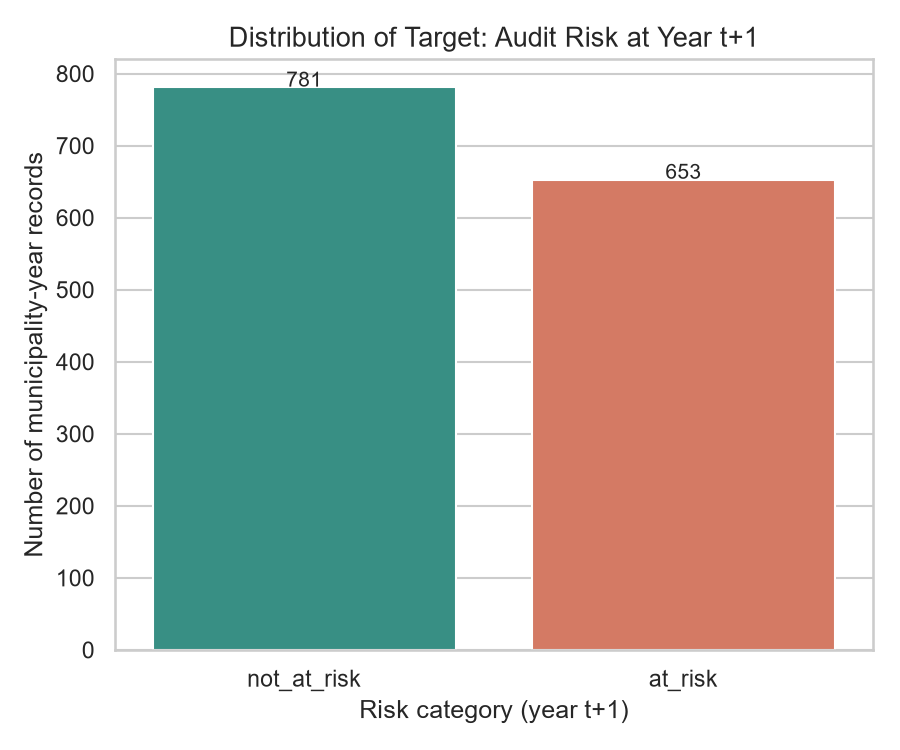

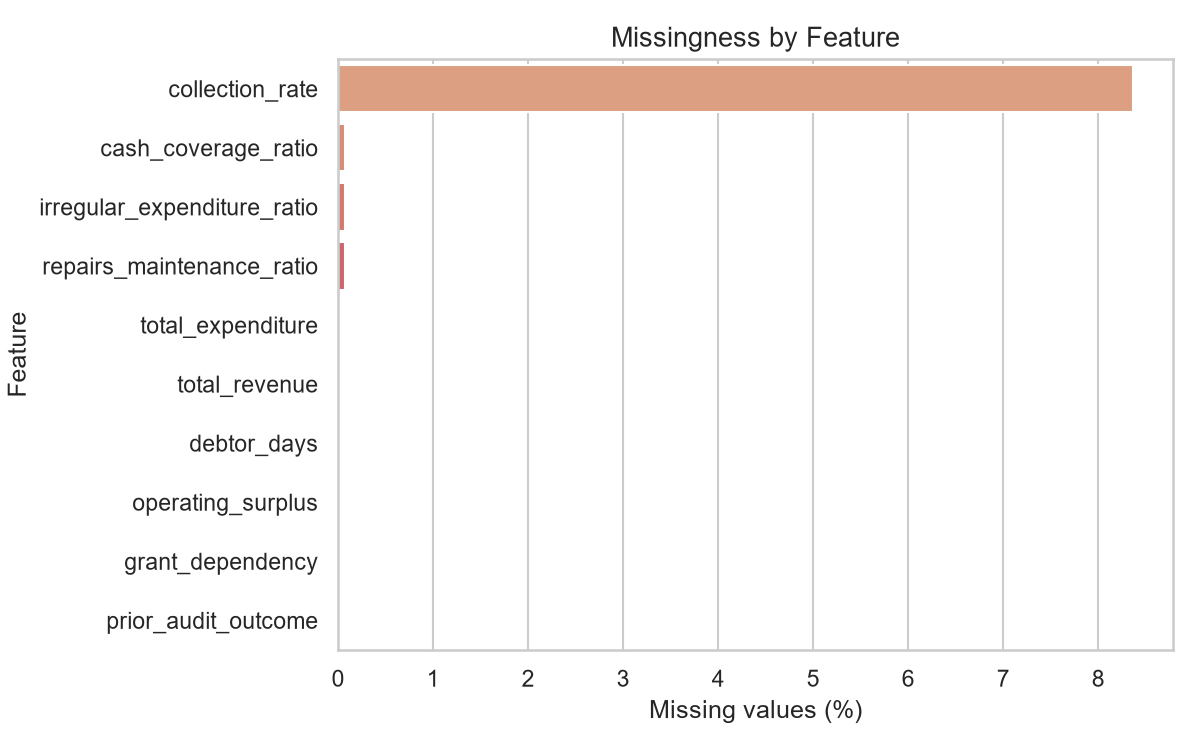

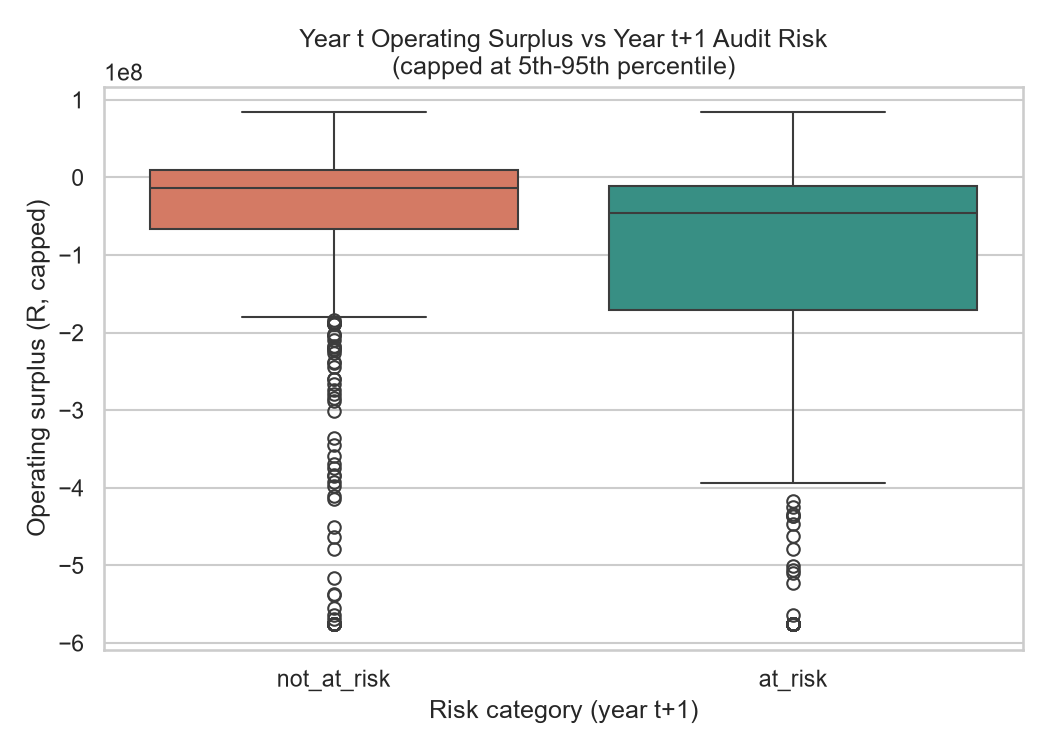

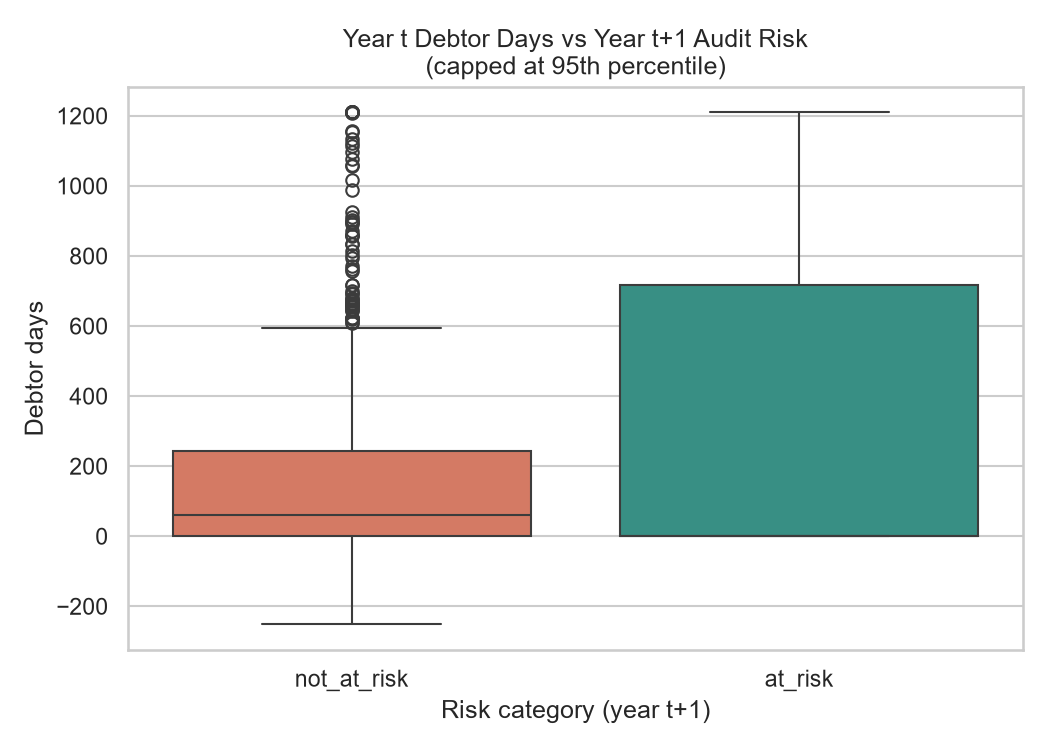

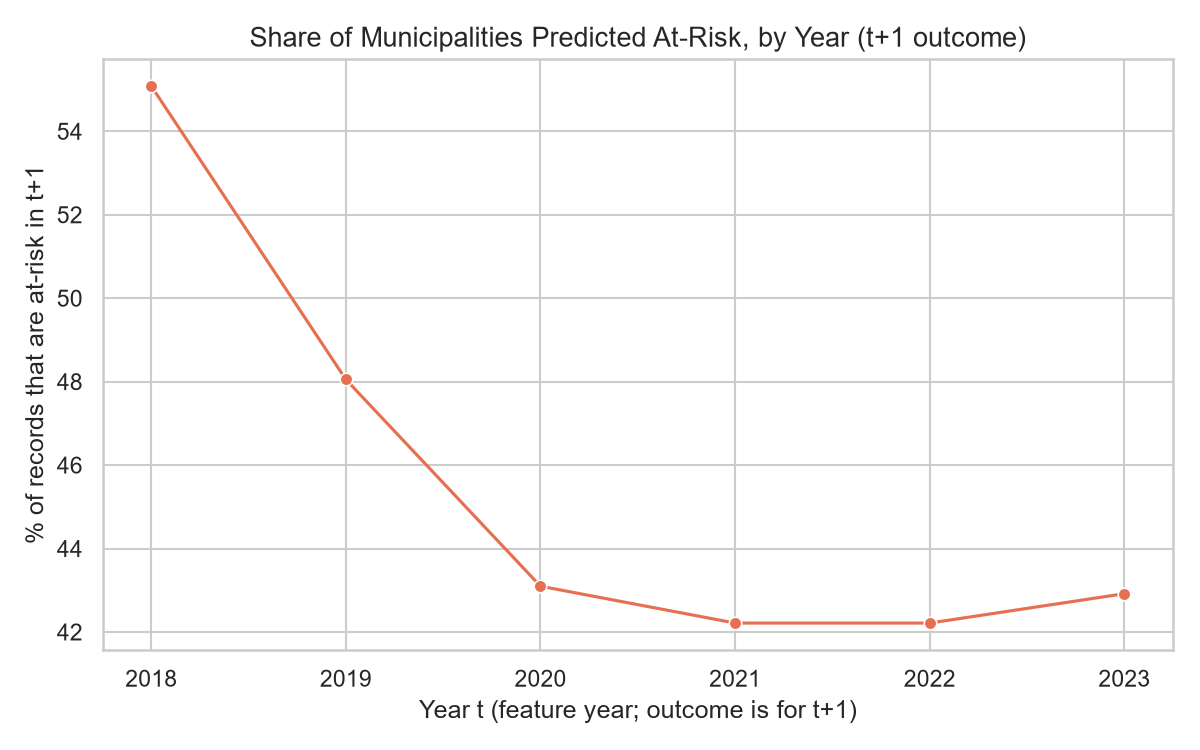

In [5]:
import visualize_q22_v2
visualize_q22_v2.main()
for name in ["01_target_distribution.png", "02_missingness_by_feature.png", "03_surplus_vs_risk.png",
             "04_debtordays_vs_risk.png", "05_risk_trend_by_year.png"]:
    show(name, 560)

In [6]:
# Numbers quoted in the interpretations of Figures 3 and 4
g = df.groupby("target_next_year")
display((g["operating_surplus"].quantile([0.25, 0.5, 0.75]).unstack() / 1e6).rename(columns=lambda q: f"surplus Q{q} (R m)"))
display(g["debtor_days"].quantile([0.25, 0.5, 0.75]).unstack().rename(columns=lambda q: f"debtor days Q{q}"))

,surplus Q0.25 (R m),surplus Q0.5 (R m),surplus Q0.75 (R m)
target_next_year,,,
at_risk,-171.389,-45.775,-11.264
not_at_risk,-66.687,-13.392,9.934


,debtor days Q0.25,debtor days Q0.5,debtor days Q0.75
target_next_year,,,
at_risk,0.000,0.000,718.196
not_at_risk,0.000,61.782,243.175


## 2.3 Time-based train, validation and test split
Split by feature year before any transformation is learned: train 2018–2021, validation 2022, test 2023 (used once, in Question 5.3).

In [7]:
import split_q23_v2
split_q23_v2.main()
splits = {name: pd.read_csv(ROOT / "data" / "processed" / f"{name}.csv") for name in ["train", "val", "test"]}
display(pd.DataFrame({name: {"years": f"{s['financial_year_end.year'].min()}–{s['financial_year_end.year'].max()}", "records": len(s),
                             "at_risk": int((s.target_next_year == "at_risk").sum()),
                             "at_risk share": round((s.target_next_year == "at_risk").mean(), 3)}
                      for name, s in splits.items()}).T)

Years present (feature year t): [np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]

Train years: [np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021)] -> 950 rows
Validation year: 2022 -> 244 rows
Test year: 2023 -> 240 rows

train class balance:
target_next_year
not_at_risk    503
at_risk        447
Name: count, dtype: int64

val class balance:
target_next_year
not_at_risk    141
at_risk        103
Name: count, dtype: int64

test class balance:
target_next_year
not_at_risk    137
at_risk        103
Name: count, dtype: int64

Saved train.csv, val.csv, test.csv to C:\Users\tshin\OneDrive\Desktop\TUT\IDA\IDAproject-Tshinavhe\data\processed/


,years,records,at_risk,at_risk share
train,2018–2021,950,447,0.471
val,2022–2022,244,103,0.422
test,2023–2023,240,103,0.429


## 2.4 Preparation pipeline
One scikit-learn `ColumnTransformer` (median imputation and scaling for the nine numbers, most-frequent imputation and one-hot encoding for `prior_audit_outcome`), fitted on the training split only.

In [8]:
import pipeline_q24
pipeline_q24.main()
print("Numeric features:", pipeline_q24.NUMERIC_FEATURES)
print("Categorical features:", pipeline_q24.CATEGORICAL_FEATURES)
pipeline_q24.build_pipeline()

Raw shapes -> train: (950, 10) val: (244, 10) test: (240, 10)



Transformed feature count: 11
Feature names: ['num__total_revenue', 'num__total_expenditure', 'num__operating_surplus', 'num__cash_coverage_ratio', 'num__collection_rate', 'num__debtor_days', 'num__repairs_maintenance_ratio', 'num__irregular_expenditure_ratio', 'num__grant_dependency', 'cat__prior_audit_outcome_at_risk', 'cat__prior_audit_outcome_not_at_risk']

Saved fitted preprocessor to C:\Users\tshin\OneDrive\Desktop\TUT\IDA\IDAproject-Tshinavhe\data\processed\preprocessor.joblib
Saved X_train.csv, y_train.csv  (shape (950, 11))
Saved X_val.csv, y_val.csv  (shape (244, 11))
Saved X_test.csv, y_test.csv  (shape (240, 11))

Class balance check after target encoding (0=not_at_risk, 1=at_risk):
  train: {0: 0.53, 1: 0.47}
  val: {0: 0.58, 1: 0.42}
  test: {0: 0.57, 1: 0.43}

Note on class imbalance: the target is only mildly imbalanced (roughly 55/45), so class_weight='balanced' at the model-training step is a reasonable, simpler alternative to oversampling (e.g. SMOTE) — document thi

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``